# Exercícios


1.   Utilize a função make_blobs da biblioteca sklearn.datasets para criar um banco de dados com 400 amostras e duas classes de dados, com `cluster_std`=3.00 e `random_state`=1;
2.   Utilize as técnicas de pré-processamento de dados (Normal distribution, Min Max scaling, L1 and L2 normalizations) no banco de dados e visualize os resultados após cada etapa;
3. **Building k-Nearest Neighbors model.** Crie um modelo utilizando  o algoritmo KNN para classificação dos dados com o parâmetro `n_neighbors`=3, com separação de 70% do banco de dados para o treinamento e 30% para os testes.
4. **Evaluating the Model.** Avalie a acurácia do seu modelo KNN com os dados "brutos", antes de aplicar as técnicas de normalização.
5. Após cada etapa de pré-processamento, treine o modelo KNN novamente com o banco de dados normalizado. Analize as métricas (acurácia) e comente os resultados.



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import make_blobs
from sklearn import preprocessing

In [ ]:
# Exercício 1.

X, y = make_blobs(
    n_samples=400,
    centers=2,
    cluster_std=3.00,
    random_state=1
)

print("Formato dos dados:", X.shape)
print("Formato das classes:", y.shape)

Formato dos dados: (400, 2)
Formato das classes: (400,)


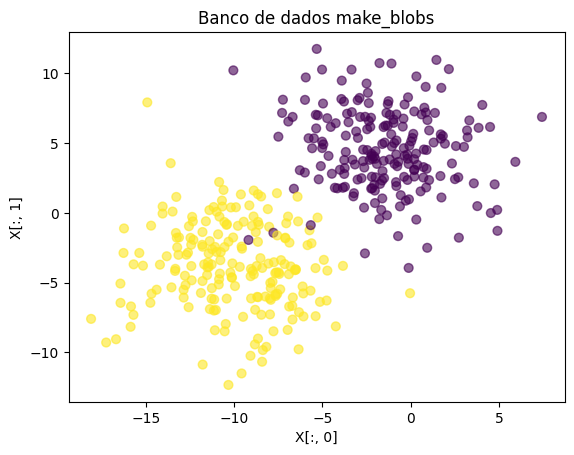

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, alpha=0.6)

plt.title("Banco de dados make_blobs")
plt.xlabel("X[:, 0]")
plt.ylabel("X[:, 1]")

plt.show()

O banco de dados possui 400 amostras, duas características e duas classes. O parâmetro cluster_std=3.00 deixa os grupos mais espalhados.

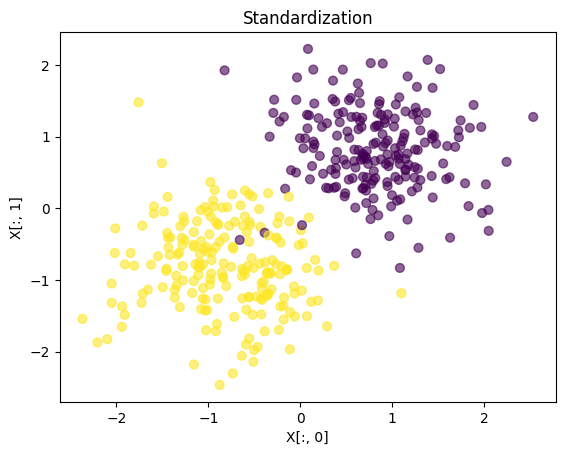

Média: [-5.81808907e-16  4.27435864e-17]
Desvio padrão: [1. 1.]


In [ ]:
# Exercício 2.

X_std = preprocessing.scale(X)

plt.scatter(X_std[:, 0], X_std[:, 1], c=y, s=40, alpha=0.6)

plt.title("Standardization")
plt.xlabel("X[:, 0]")
plt.ylabel("X[:, 1]")

plt.show()

print("Média:", X_std.mean(axis=0))
print("Desvio padrão:", X_std.std(axis=0))

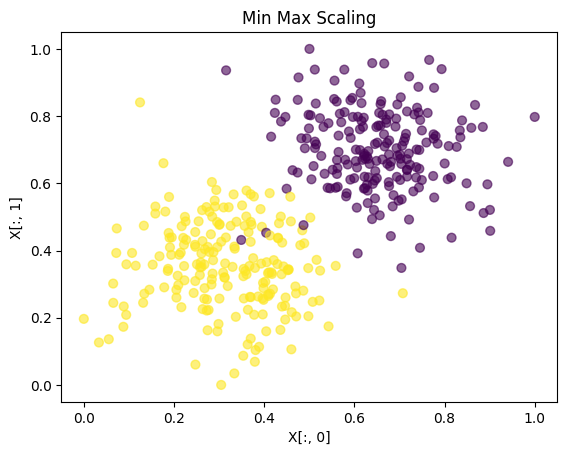

In [ ]:
data_scaler = preprocessing.MinMaxScaler(feature_range=(0, 1))

X_minmax = data_scaler.fit_transform(X)

plt.scatter(X_minmax[:, 0], X_minmax[:, 1], c=y, s=40, alpha=0.6)

plt.title("Min Max Scaling")
plt.xlabel("X[:, 0]")
plt.ylabel("X[:, 1]")

plt.show()

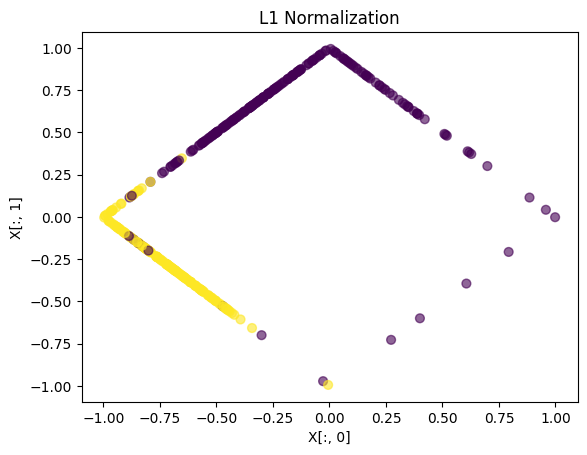

In [ ]:
X_l1 = preprocessing.normalize(X, norm='l1')

plt.scatter(X_l1[:, 0], X_l1[:, 1], c=y, s=40, alpha=0.6)

plt.title("L1 Normalization")
plt.xlabel("X[:, 0]")
plt.ylabel("X[:, 1]")

plt.show()

In [ ]:
print("Soma das linhas:")
print(X_l1.sum(axis=1)[:10])

Soma das linhas:
[-0.3605204  -0.01201947 -1.         -1.         -1.         -0.92724973
 -1.         -1.         -0.58430159  1.        ]


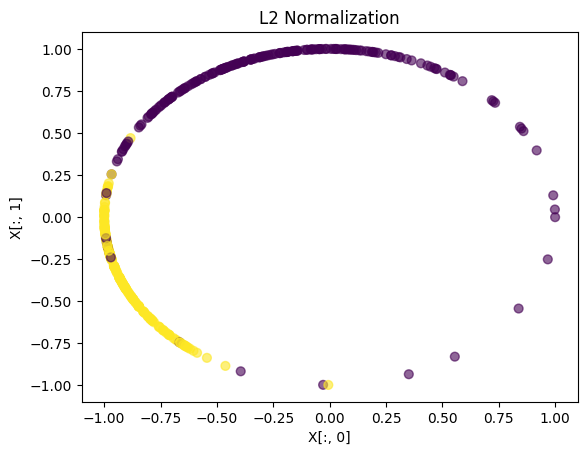

In [ ]:
X_l2 = preprocessing.normalize(X, norm='l2')

plt.scatter(X_l2[:, 0], X_l2[:, 1], c=y, s=40, alpha=0.6)

plt.title("L2 Normalization")
plt.xlabel("X[:, 0]")
plt.ylabel("X[:, 1]")

plt.show()

In [ ]:
print("Norma das linhas:")

for i in range(5):
    print(np.sqrt(sum(X_l2[i] ** 2)))

Norma das linhas:
1.0
1.0
0.9999999999999999
1.0
1.0


Cada técnica modifica os dados de uma maneira diferente. A Standardization deixa os dados com média próxima de 0 e desvio padrão próximo de 1. O Min Max Scaling coloca os valores entre 0 e 1. As normalizações L1 e L2 normalizam os valores de cada amostra.

In [ ]:
# Exercício 3.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

Dados de treinamento: (280, 2)
Dados de teste: (120, 2)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

O modelo KNN foi criado com 3 vizinhos próximos. Foram utilizados 70% dos dados para treinamento e 30% para teste.

In [ ]:
# Exercício 4.

from sklearn.metrics import accuracy_score

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Acurácia dos dados brutos:", accuracy)

Acurácia dos dados brutos: 0.9833333333333333


In [ ]:
from sklearn.metrics import confusion_matrix

result = confusion_matrix(y_test, y_pred)

print("Matriz de Confusão:")
print(result)

Matriz de Confusão:
[[60  2]
 [ 0 58]]


A acurácia mostra a porcentagem de classificações realizadas corretamente pelo KNN utilizando os dados brutos, sem nenhuma técnica de pré-processamento.

In [ ]:
# Exercício 5.

from sklearn.metrics import accuracy_score

def testar_knn(X_dados, nome):

    X_train, X_test, y_train, y_test = train_test_split(
        X_dados,
        y,
        test_size=0.3,
        random_state=1
    )

    knn = KNeighborsClassifier(n_neighbors=3)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print(nome)
    print("Acurácia:", accuracy)
    print("-" * 30)

    return accuracy

In [ ]:
acc_bruto = testar_knn(X, "Dados Brutos")

Dados Brutos
Acurácia: 0.9833333333333333
------------------------------


In [ ]:
acc_std = testar_knn(X_std, "Standardization")

Standardization
Acurácia: 0.9833333333333333
------------------------------


In [ ]:
acc_minmax = testar_knn(X_minmax, "Min Max Scaling")

Min Max Scaling
Acurácia: 0.9833333333333333
------------------------------


In [ ]:
acc_l1 = testar_knn(X_l1, "L1 Normalization")

L1 Normalization
Acurácia: 0.9666666666666667
------------------------------


In [ ]:
acc_l2 = testar_knn(X_l2, "L2 Normalization")

L2 Normalization
Acurácia: 0.9666666666666667
------------------------------


In [ ]:
resultados = pd.DataFrame({
    "Técnica": [
        "Dados Brutos",
        "Standardization",
        "Min Max",
        "L1",
        "L2"
    ],
    "Acurácia": [
        acc_bruto,
        acc_std,
        acc_minmax,
        acc_l1,
        acc_l2
    ]
})

print(resultados)

           Técnica  Acurácia
0     Dados Brutos  0.983333
1  Standardization  0.983333
2          Min Max  0.983333
3               L1  0.966667
4               L2  0.966667


A acurácia do KNN pode mudar de acordo com a técnica de pré-processamento utilizada. Isso acontece porque o KNN utiliza distância entre os pontos para realizar a classificação.

A técnica que apresentar a maior acurácia será a que teve o melhor desempenho neste conjunto de dados.